In [ ]:

import pandas as pd
import numpy as np

# Make sure the filename matches exactly what's in your sidebar
file_path = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(file_path)

print("=" * 70)
print("1. SHAPE")
print(df.shape)

print("\n" + "=" * 70)
print("2. DTYPES")
print(df.dtypes)

print("\n" + "=" * 70)
print("3. MISSING VALUES (per column)")
print(df.isnull().sum())

print("\n" + "=" * 70)
print("4. TOTALCHARGES AS TEXT — count of non-numeric-looking entries")
# Convert to numeric, coerce errors -> NaN reveals hidden blanks
tc_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Rows where TotalCharges is NOT numeric:", tc_numeric.isna().sum())
print("\nSample of those rows (customerID, tenure, MonthlyCharges, TotalCharges):")
print(df.loc[tc_numeric.isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]].head(15))

print("\n" + "=" * 70)
print("5. TARGET DISTRIBUTION (Churn)")
print(df["Churn"].value_counts())
print("\nProportions:")
print(df["Churn"].value_counts(normalize=True).round(4))

print("\n" + "=" * 70)
print("6. DUPLICATE ROWS (full-row)")
print("Duplicate rows:", df.duplicated().sum())

print("\n" + "=" * 70)
print("7. DUPLICATE customerID")
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())

print("\n" + "=" * 70)
print("8. CATEGORICAL COLUMNS — unique values per column")
cat_cols = df.select_dtypes(include="object").columns.tolist()
for c in cat_cols:
    uniq = df[c].unique()
    if len(uniq) <= 6:
        print(f"{c}: {sorted(uniq.tolist())}")
    else:
        print(f"{c}: {len(uniq)} unique values (too many to print)")

print("\n" + "=" * 70)
print("9. NUMERIC SUMMARY")
print(df.describe())

1. SHAPE
(7043, 21)

2. DTYPES
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

3. MISSING VALUES (per column)
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contr

In [ ]:
# Cell 4: Final Stage 1 cleaning & leakage audit
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# 1. Leakage Audit: Drop ID
df = df.drop(columns=["customerID"])
print("1. Dropped customerID. New shape:", df.shape)

# 2. Target Encoding
# Map 'Yes' to 1 and 'No' to 0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
print("\n2. Target encoded. Churn distribution:")
print(df["Churn"].value_counts())

# 3. Fix TotalCharges
# Convert to numeric, turn blanks into NaN, fill NaN with 0.0, then cast to float
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)
print("\n3. TotalCharges fixed. Missing values left:", df["TotalCharges"].isnull().sum())
print("TotalCharges dtype:", df["TotalCharges"].dtype)

# 4. Leakage Audit: Identify potential leakage columns
# (In this dataset, none of the remaining 19 features are leakage. They are all known at prediction time.)
print("\n4. Remaining columns:")
print(df.columns.tolist())

1. Dropped customerID. New shape: (7043, 20)

2. Target encoded. Churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

3. TotalCharges fixed. Missing values left: 0
TotalCharges dtype: float64

4. Remaining columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


/tmp/ipykernel_3440/465415151.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='Set2')


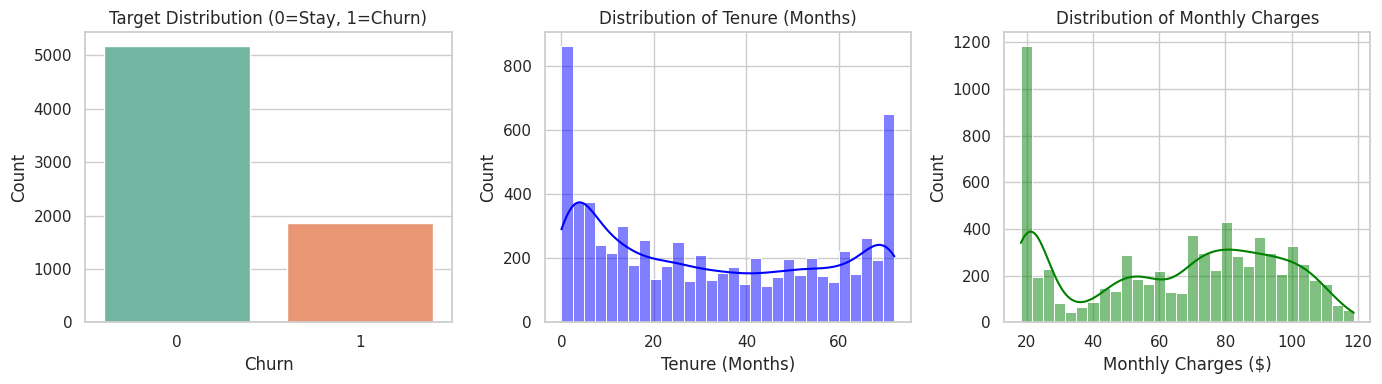

In [ ]:
# Cell 5: Univariate Analysis
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df is already loaded and cleaned from Cell 4
# Setup plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 4))

# 1. Target Distribution
plt.subplot(1, 3, 1)
sns.countplot(data=df, x='Churn', palette='Set2')
plt.title('Target Distribution (0=Stay, 1=Churn)')
plt.ylabel('Count')

# 2. Tenure Distribution
plt.subplot(1, 3, 2)
sns.histplot(data=df, x='tenure', bins=30, kde=True, color='blue')
plt.title('Distribution of Tenure (Months)')
plt.xlabel('Tenure (Months)')

# 3. Monthly Charges Distribution
plt.subplot(1, 3, 3)
sns.histplot(data=df, x='MonthlyCharges', bins=30, kde=True, color='green')
plt.title('Distribution of Monthly Charges')
plt.xlabel('Monthly Charges ($)')

plt.tight_layout()
plt.show()

/tmp/ipykernel_3440/2336317811.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='tenure', palette='Set2')
/tmp/ipykernel_3440/2336317811.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette='Set2')
/tmp/ipykernel_3440/2336317811.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=contract_churn, x='Contract', y='Churn', palette='viridis')


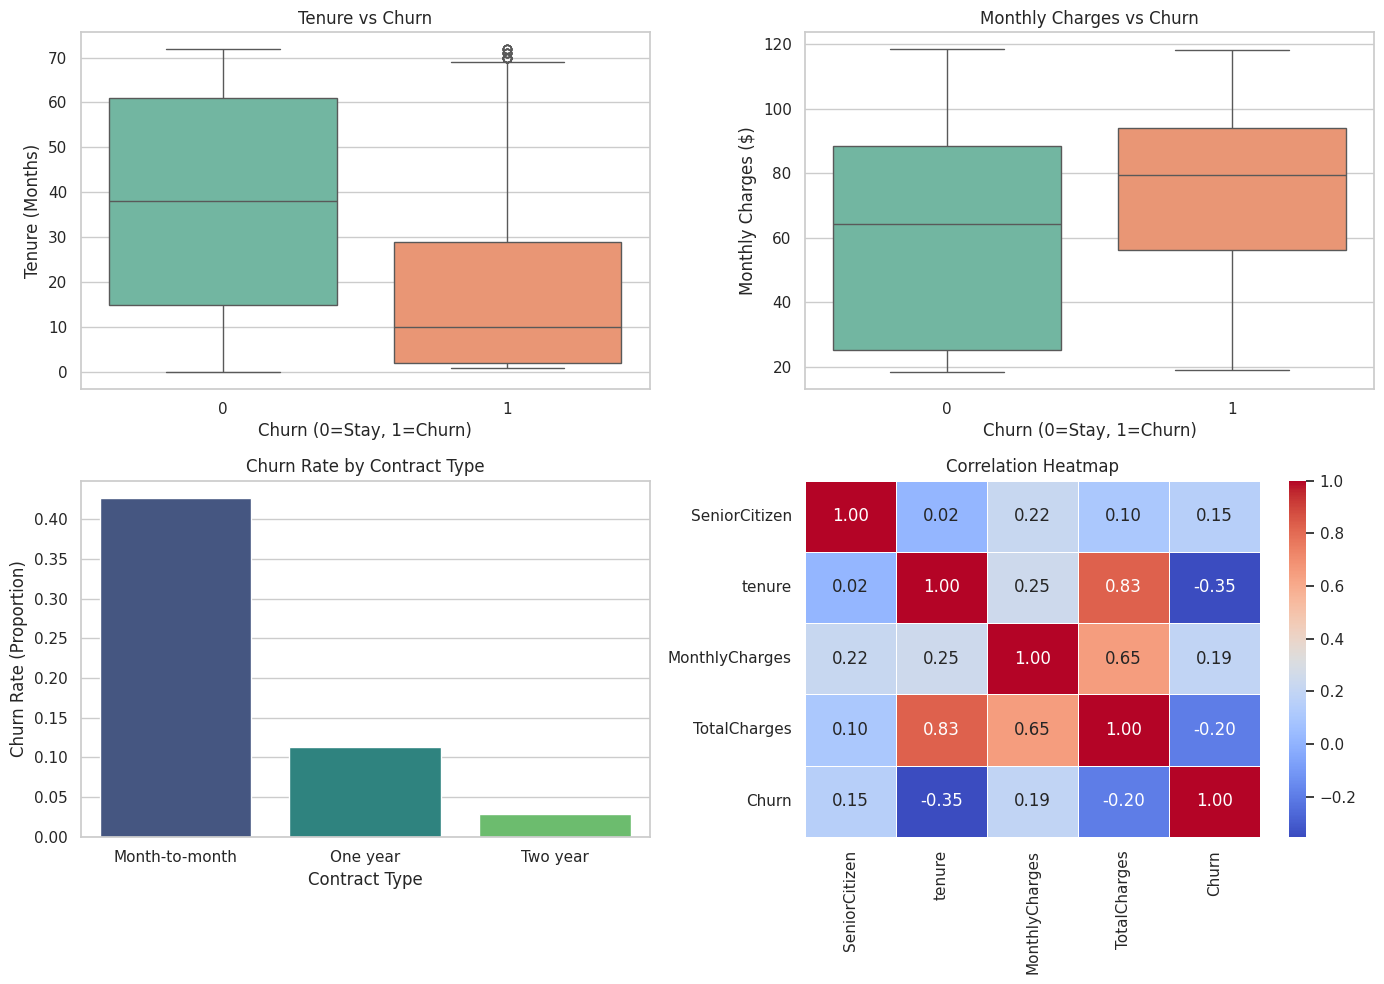

In [ ]:
# Cell 6: Bivariate Analysis
plt.figure(figsize=(14, 10))

# 1. Tenure vs Churn
plt.subplot(2, 2, 1)
sns.boxplot(data=df, x='Churn', y='tenure', palette='Set2')
plt.title('Tenure vs Churn')
plt.xlabel('Churn (0=Stay, 1=Churn)')
plt.ylabel('Tenure (Months)')

# 2. MonthlyCharges vs Churn
plt.subplot(2, 2, 2)
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette='Set2')
plt.title('Monthly Charges vs Churn')
plt.xlabel('Churn (0=Stay, 1=Churn)')
plt.ylabel('Monthly Charges ($)')

# 3. Contract Type vs Churn (Proportions)
plt.subplot(2, 2, 3)
# We calculate the churn rate per contract type
contract_churn = df.groupby('Contract')['Churn'].mean().reset_index()
sns.barplot(data=contract_churn, x='Contract', y='Churn', palette='viridis')
plt.title('Churn Rate by Contract Type')
plt.ylabel('Churn Rate (Proportion)')
plt.xlabel('Contract Type')

# 4. Correlation Heatmap (Numerical features only)
plt.subplot(2, 2, 4)
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()

Creating the Preprocessing Pipeline

In [ ]:
# Cell 7: Building the Preprocessing Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Identify numeric and categorical columns
# Note: 'Churn' is our target, so we exclude it from the features
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]

# 2. Create transformers for numeric and categorical data
# We use handle_unknown='ignore' in OneHotEncoder just in case the test set
# has a category the train set didn't see (avoids crashing)
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='if_binary'))
])

# 3. Combine them using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")
print(f"We have {len(numeric_features)} numeric features and {len(categorical_features)} categorical features.")

Preprocessing pipeline created successfully!
We have 3 numeric features and 16 categorical features.


Split, Baseline, and Train the First Model

In [ ]:
# Cell 8: Train/Test Split and Baseline
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# 1. Separate features (X) and target (y)
X = df.drop(columns=['Churn'])
y = df['Churn']

# 2. Train/Test Split (80/20) with Stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"Train Churn Rate: {y_train.mean():.4f}")
print(f"Test Churn Rate: {y_test.mean():.4f}")

# 3. Establish the Baseline (Predicts the majority class every time)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_preds = baseline.predict(X_test)

print("\n--- Baseline Model (Majority Class) ---")
print(f"Baseline Accuracy: {accuracy_score(y_test, baseline_preds):.4f}")
print("Baseline Classification Report:")
print(classification_report(y_test, baseline_preds, zero_division=0))

# 4. Build the Full Pipeline with Logistic Regression
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), # The ColumnTransformer from Cell 7
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

# 5. Train the model
log_reg_pipeline.fit(X_train, y_train)
log_reg_preds = log_reg_pipeline.predict(X_test)

print("\n--- Logistic Regression Pipeline ---")
print(f"Logistic Regression Accuracy: {accuracy_score(y_test, log_reg_preds):.4f}")
print("Logistic Regression Classification Report:")
print(classification_report(y_test, log_reg_preds))

Training set shape: (5634, 19)
Test set shape: (1409, 19)
Train Churn Rate: 0.2654
Test Churn Rate: 0.2654

--- Baseline Model (Majority Class) ---
Baseline Accuracy: 0.7346
Baseline Classification Report:
              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1035
           1       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409


--- Logistic Regression Pipeline ---
Logistic Regression Accuracy: 0.8055
Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



Model Comparison with Cross-Validation

In [ ]:
# Cell 9: Model Comparison with Cross-Validation
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd

# 1. Define the models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=42)
}

# 2. Define the Cross-Validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Loop through each model, build the pipeline, and cross-validate
results = []

for name, model in models.items():
    # Create a pipeline with the preprocessor and the current model
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Cross-validate using ROC-AUC and F1
    cv_results = cross_validate(
        pipeline, X_train, y_train,
        cv=cv,
        scoring=['roc_auc', 'f1'],
        n_jobs=-1
    )

    # Calculate mean and standard deviation
    auc_mean = cv_results['test_roc_auc'].mean()
    auc_std = cv_results['test_roc_auc'].std()
    f1_mean = cv_results['test_f1'].mean()
    f1_std = cv_results['test_f1'].std()

    results.append({
        'Model': name,
        'ROC-AUC Mean': round(auc_mean, 4),
        'ROC-AUC Std': round(auc_std, 4),
        'F1 Mean': round(f1_mean, 4),
        'F1 Std': round(f1_std, 4)
    })

# 4. Display the results as a sorted DataFrame
results_df = pd.DataFrame(results).sort_values(by='ROC-AUC Mean', ascending=False)
print("=== 5-Fold Cross-Validation Results ===")
print(results_df.to_string(index=False))

=== 5-Fold Cross-Validation Results ===
               Model  ROC-AUC Mean  ROC-AUC Std  F1 Mean  F1 Std
 Logistic Regression        0.8462       0.0126   0.5932  0.0299
HistGradientBoosting        0.8379       0.0066   0.5712  0.0275
       Random Forest        0.8198       0.0096   0.5443  0.0228
       Decision Tree        0.6510       0.0100   0.4864  0.0143


Hyperparameter Tuning (GridSearchCV)

In [ ]:
# Cell 10: Hyperparameter Tuning - Logistic Regression
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# 1. Create the pipeline
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

# 2. Define the parameter grid
# 'classifier__C' means the 'C' parameter of the 'classifier' step in the pipeline
# 'classifier__solver' means the solver. 'liblinear' and 'lbfgs' are good choices.
param_grid_lr = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['liblinear', 'lbfgs']
}

# 3. Setup GridSearchCV
grid_search_lr = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid_lr,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# 4. Fit the grid search (this will take a few seconds)
grid_search_lr.fit(X_train, y_train)

# 5. Print the best results
print("=== Best Logistic Regression Parameters ===")
print(grid_search_lr.best_params_)
print(f"Best ROC-AUC Score: {grid_search_lr.best_score_:.4f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
=== Best Logistic Regression Parameters ===
{'classifier__C': 10, 'classifier__solver': 'lbfgs'}
Best ROC-AUC Score: 0.8460


In [ ]:
# Cell 11: Hyperparameter Tuning - HistGradientBoosting
from sklearn.ensemble import HistGradientBoostingClassifier

# 1. Create the pipeline
hgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(random_state=42))
])

# 2. Define the parameter grid (Keep it small to save time!)
param_grid_hgb = {
    'classifier__max_iter': [100, 200],
    'classifier__learning_rate': [0.01, 0.1, 0.2],
    'classifier__max_depth': [3, 5, None]
}

# 3. Setup GridSearchCV
grid_search_hgb = GridSearchCV(
    estimator=hgb_pipeline,
    param_grid=param_grid_hgb,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# 4. Fit the grid search (this will take a bit longer, maybe 30-60 seconds)
grid_search_hgb.fit(X_train, y_train)

# 5. Print the best results
print("=== Best HistGradientBoosting Parameters ===")
print(grid_search_hgb.best_params_)
print(f"Best ROC-AUC Score: {grid_search_hgb.best_score_:.4f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits
=== Best HistGradientBoosting Parameters ===
{'classifier__learning_rate': 0.01, 'classifier__max_depth': 5, 'classifier__max_iter': 200}
Best ROC-AUC Score: 0.8467


Final Test Set Evaluation

=== Final Test Set Metrics (HistGradientBoosting) ===
Accuracy:  0.8013
Precision: 0.6865
Recall:    0.4626
F1-Score:  0.5527
ROC-AUC:   0.8439
PR-AUC (Average Precision): 0.6517

=== Confusion Matrix ===
[[956  79]
 [201 173]]
True Negatives (TN):  956 - Correctly predicted STAY
False Positives (FP): 79 - Wrongly predicted CHURN
False Negatives (FN): 201 - Missed actual CHURN
True Positives (TP):  173 - Correctly predicted CHURN


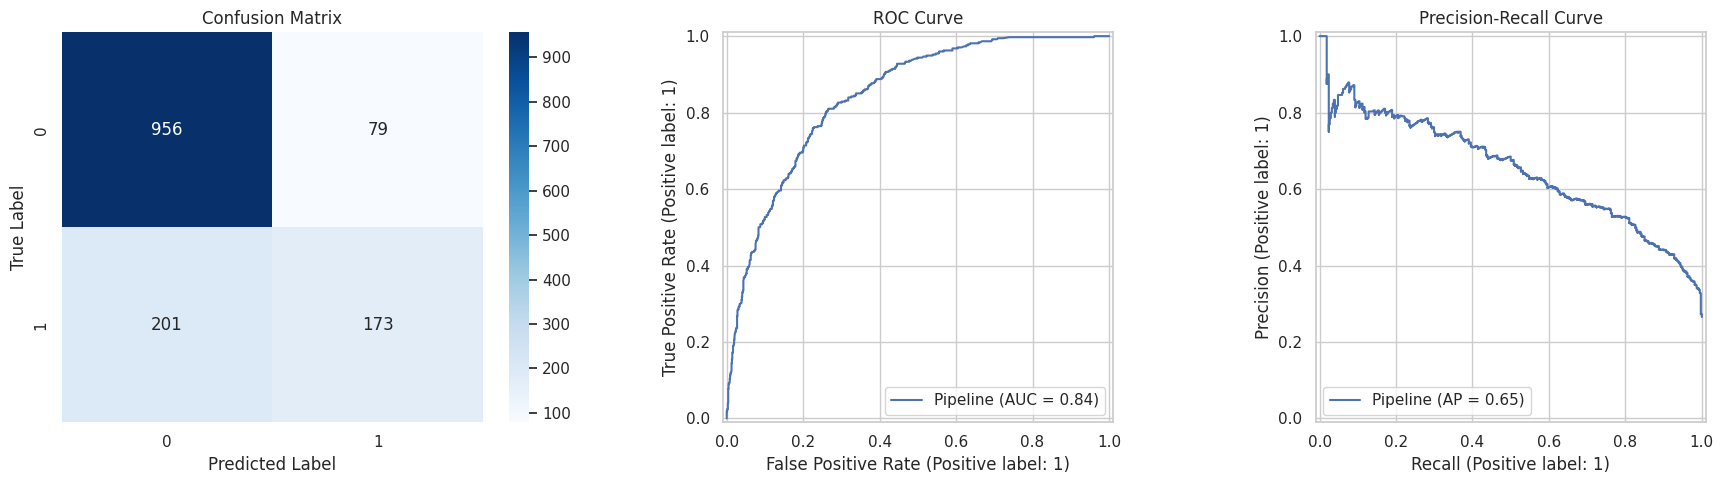

In [ ]:
# Cell 12: Final Evaluation on the Test Set
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Use the best model found by GridSearchCV
best_model = grid_search_hgb.best_estimator_

# 2. Predict on the test set
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1] # Probability of churn (Class 1)

# 3. Print Metrics
print("=== Final Test Set Metrics (HistGradientBoosting) ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")
print(f"PR-AUC (Average Precision): {average_precision_score(y_test, y_proba):.4f}")

# 4. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\n=== Confusion Matrix ===")
print(cm)
print(f"True Negatives (TN):  {cm[0,0]} - Correctly predicted STAY")
print(f"False Positives (FP): {cm[0,1]} - Wrongly predicted CHURN")
print(f"False Negatives (FN): {cm[1,0]} - Missed actual CHURN")
print(f"True Positives (TP):  {cm[1,1]} - Correctly predicted CHURN")

# 5. Plot Confusion Matrix, ROC, and PR Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Plot ROC Curve
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=axes[1])
axes[1].set_title('ROC Curve')

# Plot Precision-Recall Curve
PrecisionRecallDisplay.from_estimator(best_model, X_test, y_test, ax=axes[2])
axes[2].set_title('Precision-Recall Curve')

plt.tight_layout()
plt.show()

=== Optimal Threshold Analysis ===
Optimal Threshold: 0.10
Minimum Financial Cost: $44,000
Recall at this threshold: 0.9626
Precision at this threshold: 0.3750


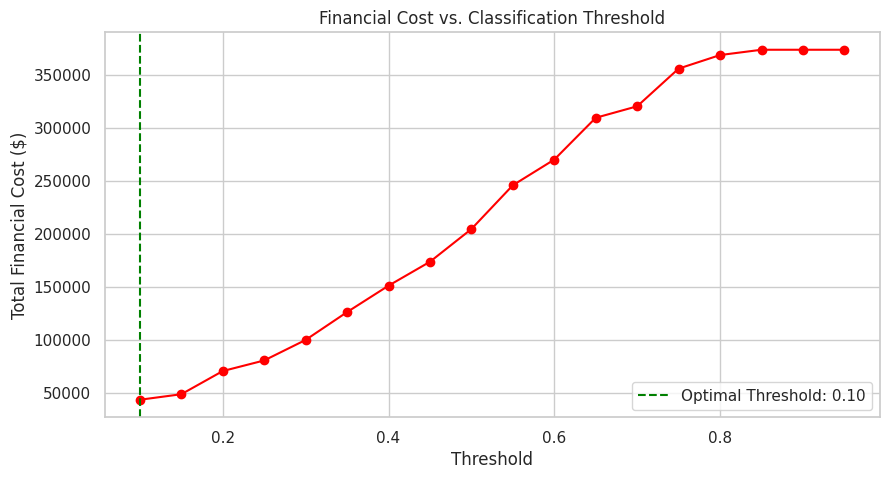

In [ ]:
# Cell 13: Threshold Tuning
import numpy as np
import matplotlib.pyplot as plt

# 1. Get the predicted probabilities for the positive class (Churn)
y_proba = best_model.predict_proba(X_test)[:, 1]

# 2. Define a range of thresholds to test
thresholds = np.arange(0.1, 1.0, 0.05)
costs = []
recalls = []
precisions = []

for thresh in thresholds:
    # Predict using the current threshold
    y_pred_thresh = (y_proba >= thresh).astype(int)

    # Calculate confusion matrix elements
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_thresh).ravel()

    # Calculate business cost
    cost = (fn * 1000) + (fp * 50)
    costs.append(cost)

    # Calculate recall and precision
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recalls.append(recall)
    precisions.append(precision)

# 3. Find the threshold that minimizes cost
min_cost_idx = np.argmin(costs)
best_threshold = thresholds[min_cost_idx]
min_cost = costs[min_cost_idx]

print(f"=== Optimal Threshold Analysis ===")
print(f"Optimal Threshold: {best_threshold:.2f}")
print(f"Minimum Financial Cost: ${min_cost:,}")
print(f"Recall at this threshold: {recalls[min_cost_idx]:.4f}")
print(f"Precision at this threshold: {precisions[min_cost_idx]:.4f}")

# 4. Plot the results
plt.figure(figsize=(10, 5))
plt.plot(thresholds, costs, marker='o', color='red')
plt.axvline(x=best_threshold, color='green', linestyle='--', label=f'Optimal Threshold: {best_threshold:.2f}')
plt.title('Financial Cost vs. Classification Threshold')
plt.xlabel('Threshold')
plt.ylabel('Total Financial Cost ($)')
plt.legend()
plt.grid(True)
plt.show()

=== Top 15 Most Important Features (Permutation Importance) ===
         Feature  Importance Mean  Importance Std
        Contract         0.151270        0.008923
          tenure         0.044527        0.003088
 InternetService         0.017923        0.003751
  OnlineSecurity         0.009590        0.001929
  MonthlyCharges         0.008647        0.002953
    TotalCharges         0.006169        0.002042
     TechSupport         0.003832        0.001910
PaperlessBilling         0.003142        0.001435
   PaymentMethod         0.002569        0.001334
 StreamingMovies         0.001769        0.000987
   MultipleLines         0.001710        0.001056
    PhoneService         0.000842        0.000359
   SeniorCitizen         0.000821        0.000514
    OnlineBackup         0.000740        0.000867
          gender         0.000026        0.000802


/tmp/ipykernel_3440/869027270.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=perm_df.head(15), x='Importance Mean', y='Feature', palette='viridis')


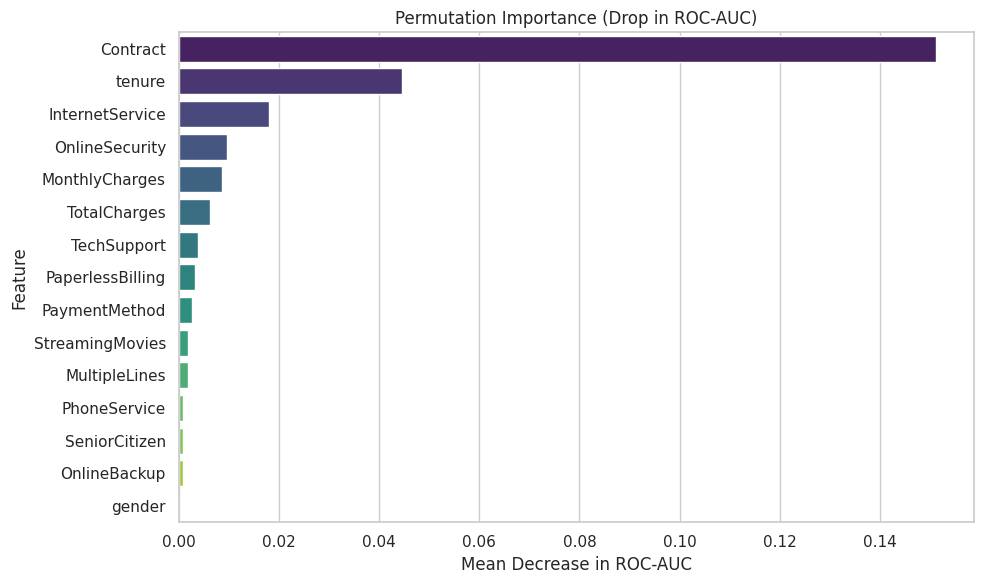

In [ ]:
# Cell 14 (Fixed): Permutation Importance using original feature names
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate permutation importance
perm_importance = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=10, random_state=42,
    scoring='roc_auc', n_jobs=-1
)

# 2. Create DataFrame using the ORIGINAL feature names from X_test
# (Because permutation_importance shuffles the original columns, not the encoded ones)
perm_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance Mean': perm_importance.importances_mean,
    'Importance Std': perm_importance.importances_std
}).sort_values(by='Importance Mean', ascending=False)

print("=== Top 15 Most Important Features (Permutation Importance) ===")
print(perm_df.head(15).to_string(index=False))

# 3. Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=perm_df.head(15), x='Importance Mean', y='Feature', palette='viridis')
plt.title('Permutation Importance (Drop in ROC-AUC)')
plt.xlabel('Mean Decrease in ROC-AUC')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

/tmp/ipykernel_3440/229279546.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=combined, x='Coefficient', y='Feature', palette='coolwarm')


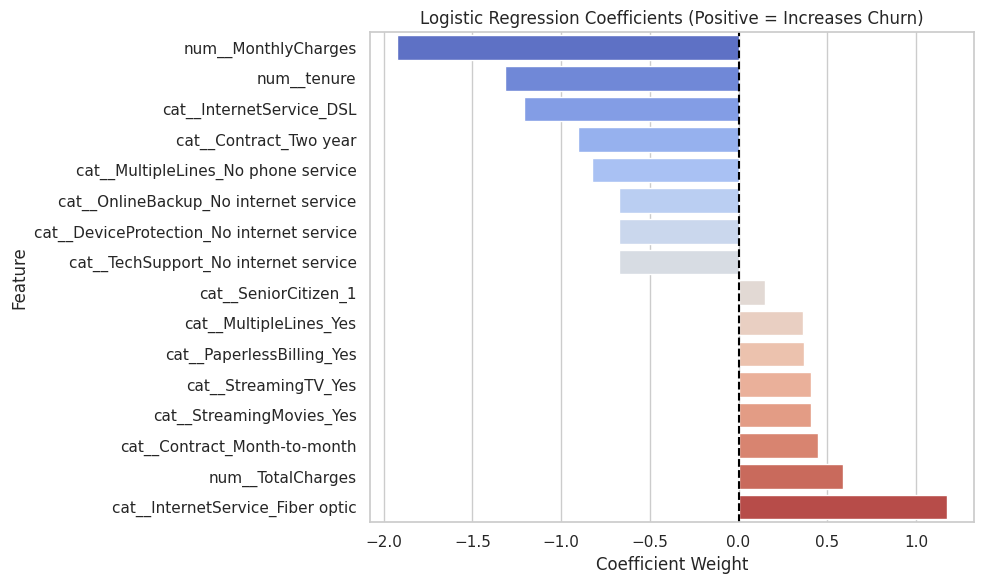

In [ ]:
# Cell 15 (Corrected): Logistic Regression Coefficients
from sklearn.linear_model import LogisticRegression

# 1. Get best LR parameters
best_C = grid_search_lr.best_params_['classifier__C']
best_solver = grid_search_lr.best_params_['classifier__solver']

# 2. Train LR pipeline
lr_best = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(C=best_C, solver=best_solver, random_state=42, max_iter=1000))
])
lr_best.fit(X_train, y_train)

# 3. Extract coefficients and feature names safely
coefficients = lr_best.named_steps['classifier'].coef_[0]
feature_names = lr_best.named_steps['preprocessor'].get_feature_names_out()

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', ascending=False)

# 4. Plot top positive and negative
top_pos = coef_df.head(8)
top_neg = coef_df.tail(8)
combined = pd.concat([top_pos, top_neg]).sort_values(by='Coefficient')

plt.figure(figsize=(10, 6))
sns.barplot(data=combined, x='Coefficient', y='Feature', palette='coolwarm')
plt.axvline(x=0, color='black', linestyle='--')
plt.title('Logistic Regression Coefficients (Positive = Increases Churn)')
plt.xlabel('Coefficient Weight')
plt.tight_layout()
plt.show()